# Issue #17: Forecast Evaluation and Business Interpretation

**Inputs (Issue #16, repository root):** `forecast_holdout_i16.csv` (held-out weeks: actual vs forecast with 80/95% intervals), `ts_backtest_predictions_i16.csv` (every rolling-origin backtest forecast), `ts_backtest_i16.csv` (backtest summary), `forecast_daily_i16.csv` (8-week future forecast), `time_series_daily.csv`, `time_series_hourly.csv`, `ts_tables/05_regimes.csv`; `acn_clean_sessions.csv` (Issue #9) for charger-level usage.

**Outputs (repository root):** `forecast_evaluation_i17.csv`, `forecast_metrics_i17.csv`, `eval_ts_tables/`, `eval_ts_figures/`, `forecast_findings_i17.md`

**Rules**
- Errors are always computed **per regime** (paid and recovery separately). Pooling them mixes a ~30 sessions/day level with a ~20 sessions/day level, which inflates R² and hides the bias of each model.
- Error = **forecast − actual**: positive means the forecast was too high (over-forecast). Issue #16's backtest table uses actual − forecast; the sign is converted here.
- Every number in the findings is computed in this notebook; nothing is typed in by hand.

In [1]:
from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")
import sys
ROOT = find_root("acn_clean_sessions.csv")
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

need = ["forecast_holdout_i16.csv", "ts_backtest_predictions_i16.csv", "ts_backtest_i16.csv", "forecast_daily_i16.csv",
        "time_series_daily.csv", "time_series_hourly.csv", "ts_tables/05_regimes.csv", "acn_clean_sessions.csv"]
missing = [f for f in need if not (ROOT / f).exists()]
assert not missing, f"Run Issue #16 first; missing: {missing}"

TAB, FIG = ROOT / "eval_ts_tables", ROOT / "eval_ts_figures"
TAB.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
INK, INK2, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b3"
SERIES, ACCENT = "#2a78d6", "#eb6834"
REG_COLORS = {"free": "#2a78d6", "paid": "#eb6834", "covid": "#1baf7a", "recovery": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "legend.frameon": False, "axes.axisbelow": True})
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def hhmm(h):
    m = int(round(h * 60)); return f"{m // 60 % 24:02d}:{m % 60:02d}"

daily = pd.read_csv(ROOT / "time_series_daily.csv", parse_dates=["date"]).set_index("date")
daily["holiday_name"] = daily["holiday_name"].fillna("")
hourly = pd.read_csv(ROOT / "time_series_hourly.csv", parse_dates=["datetime_local", "date"])
regimes = pd.read_csv(ROOT / "ts_tables/05_regimes.csv", parse_dates=["start", "end"]).set_index("regime")
LABEL = regimes["label"].to_dict()

holdout = pd.read_csv(ROOT / "forecast_holdout_i16.csv", parse_dates=["date"])
bt = pd.read_csv(ROOT / "ts_backtest_predictions_i16.csv", parse_dates=["date", "origin"])
bt_summary = pd.read_csv(ROOT / "ts_backtest_i16.csv")
future = pd.read_csv(ROOT / "forecast_daily_i16.csv", parse_dates=["date"]).set_index("date")

CHOSEN = holdout.groupby("regime")["model"].first().to_dict()      # model Issue #16 selected for each regime
REGS = list(CHOSEN)
for df in (holdout, bt):
    df["error"] = df["forecast"] - df["actual"]
    df["abs_error"] = df["error"].abs()
    df["dayofweek"] = df["date"].dt.dayofweek
    df["holiday_name"] = df["date"].map(daily["holiday_name"]).fillna("")
    df["campus_closure"] = df["date"].map(daily["campus_closure"]).fillna(0).astype(int)
print("Models selected in Issue #16:", CHOSEN)
print(f"Held-out days: {len(holdout)} | backtest forecasts: {len(bt):,} ({bt['model'].nunique()} models, {bt['origin'].nunique()} origins)")
print(f"Future forecast: {future.index.min().date()} -> {future.index.max().date()} ({len(future)} days)")

Models selected in Issue #16: {'paid': 'SARIMAX + closures', 'recovery': 'SARIMAX + closures + drift'}
Held-out days: 84 | backtest forecasts: 4,704 (6 models, 28 origins)
Future forecast: 2021-09-14 -> 2021-11-08 (56 days)


## 1. Forecast Evaluation

### 1.1 Evaluation metrics

| Metric | Definition | Why it is used |
|---|---|---|
| **MAE** | mean \|forecast − actual\| (sessions/day) | Directly readable: "the forecast is off by about N sessions a day" |
| **RMSE** | √mean(error²) | Penalises large misses (e.g. a missed holiday), which matter most for capacity |
| **WAPE** | Σ\|error\| / Σ actual | Scale-free, so the paid and recovery regimes can be compared; stable on low days, unlike MAPE |
| **Bias** | mean(forecast − actual) | Systematic over- or under-forecasting; for capacity, under-forecasting is the costly direction |
| **Skill vs baseline** | 1 − MAE(model) / MAE(baseline) | Whether the model is worth using over a rule a planner could apply by hand |
| **Interval coverage** | share of days inside the 80% / 95% interval | Whether the stated uncertainty can be trusted for planning buffers |
| **Interval width** | mean (hi − lo) | A wide interval with good coverage is honest but less useful |

**Not used.** *MAPE* divides by actual demand and explodes on closure days with a handful of sessions. *R² on pooled regimes* mostly measures the difference in level between the regimes, not forecast quality. It is reported per regime only, for reference.

In [2]:
def metrics(d):
    y, f, e = d["actual"], d["forecast"], d["error"]
    out = {"days": len(d), "mean_actual": y.mean(), "mean_forecast": f.mean(), "MAE": e.abs().mean(),
           "RMSE": np.sqrt((e ** 2).mean()), "WAPE": e.abs().sum() / y.sum(), "bias": e.mean(),
           "R2_within_regime": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()}
    if "lo80" in d and d["lo80"].notna().any():
        out.update({"coverage_80": d["actual"].between(d["lo80"], d["hi80"]).mean(),
                    "coverage_95": d["actual"].between(d["lo95"], d["hi95"]).mean(),
                    "width_80": (d["hi80"] - d["lo80"]).mean(), "width_95": (d["hi95"] - d["lo95"]).mean()})
    return pd.Series(out)


def group_metrics(df, keys):
    rows = [dict(zip(keys if isinstance(keys, list) else [keys], k if isinstance(k, tuple) else (k,)), **metrics(g).to_dict())
            for k, g in df.groupby(keys)]
    return pd.DataFrame(rows).set_index(keys)

hold_m = group_metrics(holdout, "regime")
hold_m.insert(0, "model", pd.Series(CHOSEN))
for reg in REGS:   # closure vs other days
    d = holdout[holdout.regime == reg]
    hold_m.loc[reg, "MAE_closure_days"] = d.loc[d.campus_closure == 1, "abs_error"].mean()
    hold_m.loc[reg, "MAE_other_days"] = d.loc[d.campus_closure == 0, "abs_error"].mean()
    hold_m.loc[reg, "closure_days"] = int(d.campus_closure.sum())
save_table(hold_m.round(4), "01_holdout_metrics")
display(Markdown("**Held-out weeks (scored once, never used for model choice)**"))
display(hold_m.style.format({c: "{:.2f}" for c in ["mean_actual", "mean_forecast", "MAE", "RMSE", "bias", "width_80", "width_95",
                                                   "MAE_closure_days", "MAE_other_days", "R2_within_regime"]}
                            | {c: "{:.1%}" for c in ["WAPE", "coverage_80", "coverage_95"]}))

**Held-out weeks (scored once, never used for model choice)**

,model,days,mean_actual,mean_forecast,MAE,RMSE,WAPE,bias,R2_within_regime,coverage_80,coverage_95,width_80,width_95,MAE_closure_days,MAE_other_days,closure_days
regime,,,,,,,,,,,,,,,,
paid,SARIMAX + closures,56.000000,29.48,25.44,5.72,6.82,19.4%,-4.04,0.79,85.7%,96.4%,18.04,26.42,6.52,5.69,2.000000
recovery,SARIMAX + closures + drift,28.000000,20.57,19.48,3.92,5.80,19.1%,-1.09,0.48,60.7%,78.6%,8.19,12.53,9.13,3.73,1.000000


### 1.2 Skill against simple baselines (rolling-origin backtest)

The held-out weeks are only 8 and 4 weeks long. The backtest repeats the forecast from many origins (each forecasting 28 days ahead using only earlier data), so its averages are far more stable. Skill is measured against the best baseline that needs no model.

,regime,model,selected,MAE,WAPE,bias,skill_vs_best_baseline,best_baseline,coverage_80
3,paid,SARIMAX + closures,True,4.45,16.8%,-0.32,+35%,8-week weekday mean,88%
4,paid,SARIMAX + closures + drift,False,4.92,18.7%,-2.31,+28%,8-week weekday mean,81%
2,paid,SARIMA (weekly),False,6.21,23.5%,+2.02,+9%,8-week weekday mean,89%
0,paid,8-week weekday mean,False,6.82,25.8%,+0.20,+0%,8-week weekday mean,nan%
1,paid,"Holt-Winters (damped, log)",False,7.67,29.0%,-0.81,-12%,8-week weekday mean,nan%
5,paid,Seasonal naive,False,7.97,30.2%,+1.17,-17%,8-week weekday mean,nan%
10,recovery,SARIMAX + closures + drift,True,3.18,20.6%,-1.49,+17%,Seasonal naive,65%
9,recovery,SARIMAX + closures,False,3.45,22.3%,-1.82,+9%,Seasonal naive,64%
8,recovery,SARIMA (weekly),False,3.47,22.5%,-1.74,+9%,Seasonal naive,64%
7,recovery,"Holt-Winters (damped, log)",False,3.55,23.0%,-1.85,+7%,Seasonal naive,nan%


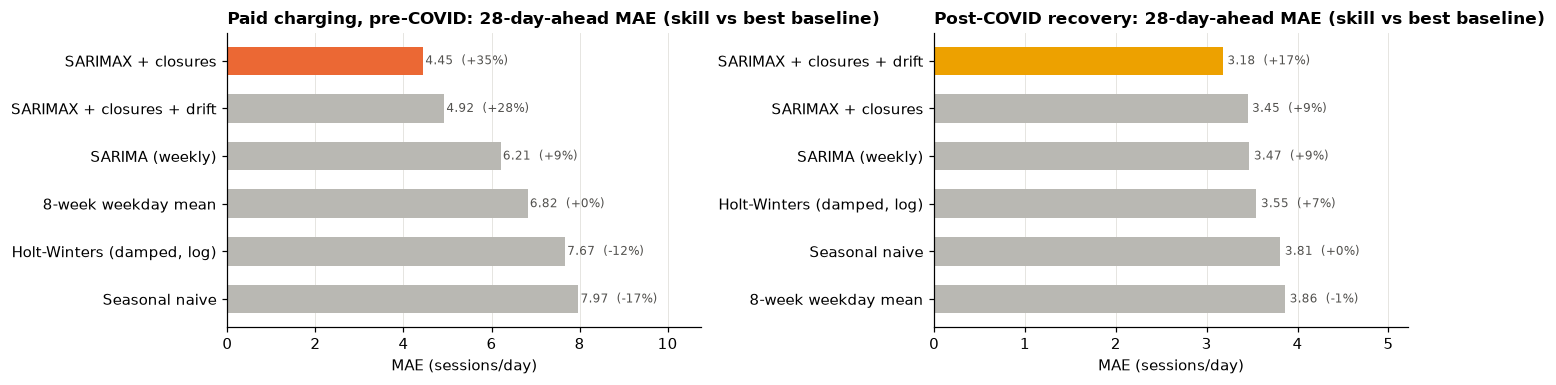

In [3]:
bt_m = group_metrics(bt, ["regime", "model"]).reset_index()
BASELINES = ["Seasonal naive", "8-week weekday mean"]
rows = []
for reg in REGS:
    b = bt_m[bt_m.regime == reg].set_index("model")
    best_base = b.loc[[m for m in BASELINES if m in b.index], "MAE"].idxmin()
    for m in b.index:
        rows.append({"regime": reg, "model": m, "selected": m == CHOSEN[reg], "MAE": b.at[m, "MAE"], "WAPE": b.at[m, "WAPE"],
                     "bias": b.at[m, "bias"], "skill_vs_best_baseline": 1 - b.at[m, "MAE"] / b.at[best_base, "MAE"],
                     "best_baseline": best_base, "coverage_80": b.at[m, "coverage_80"] if "coverage_80" in b else np.nan})
skill = save_table(pd.DataFrame(rows).sort_values(["regime", "MAE"]), "02_backtest_skill", index=False)
display(skill.style.format({"MAE": "{:.2f}", "WAPE": "{:.1%}", "bias": "{:+.2f}", "skill_vs_best_baseline": "{:+.0%}", "coverage_80": "{:.0%}"}))

fig, axes = plt.subplots(1, len(REGS), figsize=(13, 3.6))
for ax, reg in zip(np.atleast_1d(axes), REGS):
    s = skill[skill.regime == reg].sort_values("MAE", ascending=False)
    ax.barh(s["model"], s["MAE"], color=[REG_COLORS[reg] if x else NEUTRAL for x in s["selected"]], height=0.6)
    for i, (v, k) in enumerate(zip(s["MAE"], s["skill_vs_best_baseline"])):
        ax.text(v + 0.05, i, f"{v:.2f}  ({k:+.0%})", va="center", fontsize=8, color=INK2)
    ax.set(title=f"{LABEL[reg]}: 28-day-ahead MAE (skill vs best baseline)", xlabel="MAE (sessions/day)")
    ax.grid(axis="y", visible=False); ax.set_xlim(0, s["MAE"].max() * 1.35)
fig.tight_layout(); save_fig(fig, "E01_backtest_skill")

### 1.3 Actual versus forecast

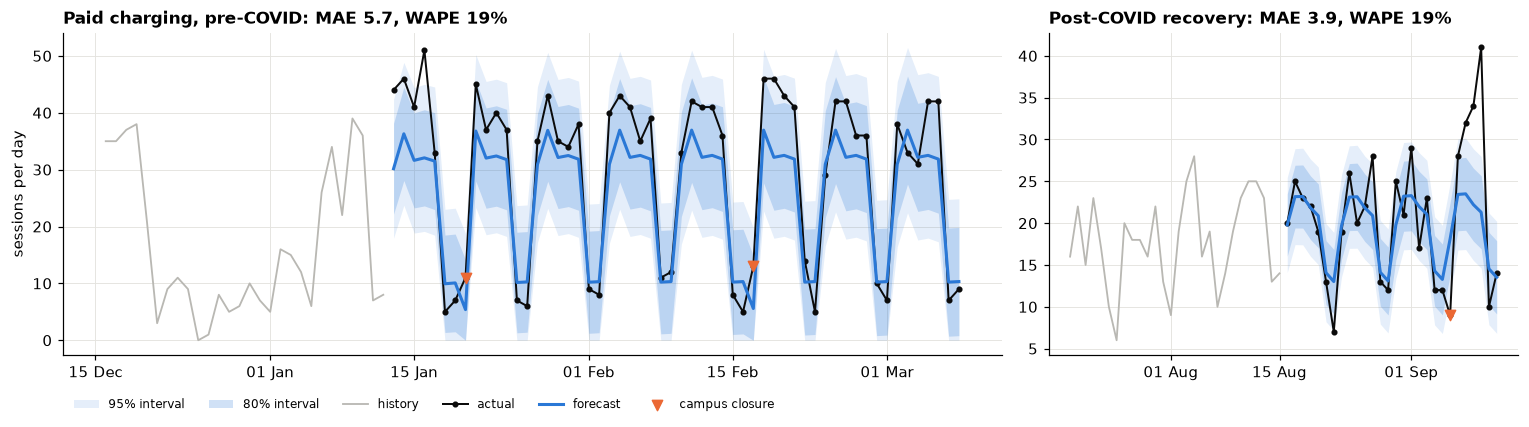

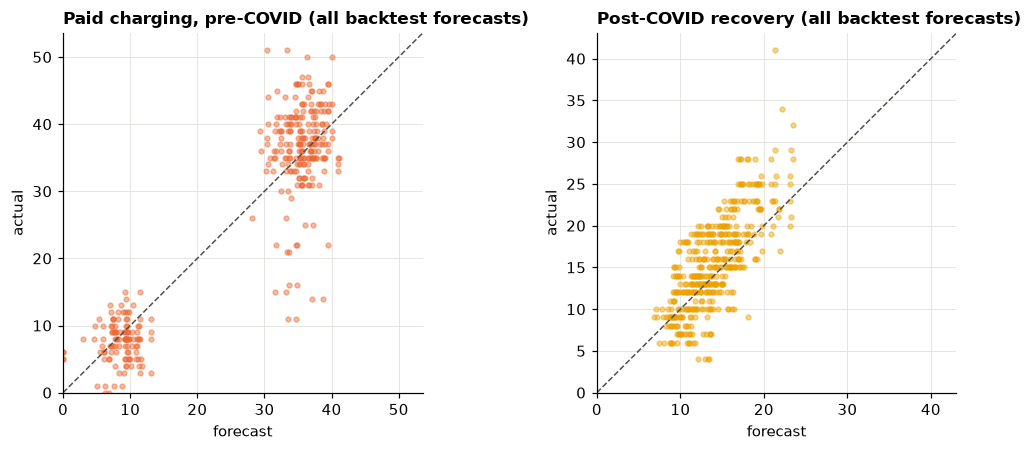

In [4]:
fig, axes = plt.subplots(1, len(REGS), figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1][:len(REGS)]})
for ax, reg in zip(np.atleast_1d(axes), REGS):
    f = holdout[holdout.regime == reg].set_index("date")
    ctx = daily.loc[f.index[0] - pd.Timedelta(days=28):f.index[0] - pd.Timedelta(days=1), "session_count"]
    ax.fill_between(f.index, f.lo95, f.hi95, color=SERIES, alpha=0.12, lw=0, label="95% interval")
    ax.fill_between(f.index, f.lo80, f.hi80, color=SERIES, alpha=0.22, lw=0, label="80% interval")
    ax.plot(ctx.index, ctx.values, color=NEUTRAL, lw=1.2, label="history")
    ax.plot(f.index, f.actual, color=INK, marker="o", ms=3, lw=1.3, label="actual")
    ax.plot(f.index, f.forecast, color=SERIES, lw=2, label="forecast")
    cl = f[f.campus_closure == 1]
    ax.scatter(cl.index, cl.actual, marker="v", s=45, color=ACCENT, zorder=4, label="campus closure")
    ax.set_title(f"{LABEL[reg]}: MAE {hold_m.at[reg, 'MAE']:.1f}, WAPE {hold_m.at[reg, 'WAPE']:.0%}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6))
np.atleast_1d(axes)[0].set_ylabel("sessions per day")
np.atleast_1d(axes)[0].legend(fontsize=8, ncol=6, loc="upper left", bbox_to_anchor=(0, -0.1))
fig.tight_layout(); save_fig(fig, "E02_holdout_actual_vs_forecast")

fig, axes = plt.subplots(1, len(REGS), figsize=(10, 4.2))
for ax, reg in zip(np.atleast_1d(axes), REGS):
    d = bt[(bt.regime == reg) & (bt.model == CHOSEN[reg])]
    lim = max(d.actual.max(), d.forecast.max()) * 1.05
    ax.scatter(d.forecast, d.actual, s=10, alpha=0.45, color=REG_COLORS[reg])
    ax.plot([0, lim], [0, lim], color=INK2, ls="--", lw=1)
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="forecast", ylabel="actual", title=f"{LABEL[reg]} (all backtest forecasts)")
    ax.set_aspect("equal")
fig.tight_layout(); save_fig(fig, "E03_actual_vs_forecast_scatter")

### 1.4 Forecasting errors

What the errors depend on: the forecast horizon (how many days ahead), the weekday, closures, and whether they are random or follow a pattern. The backtest forecasts of the selected model are used because they contain many more days than the held-out weeks.

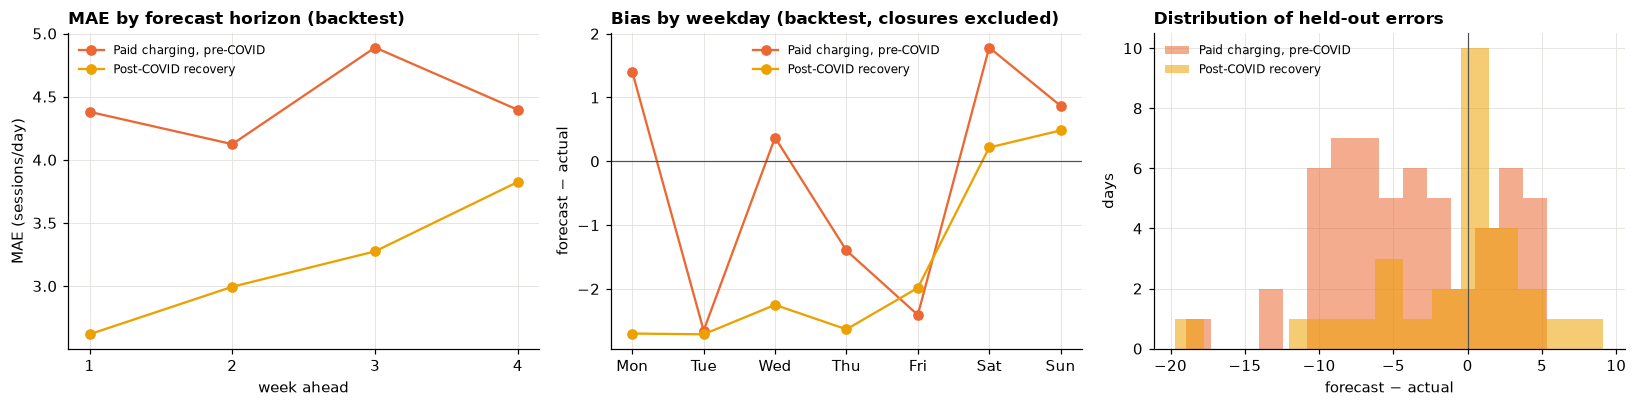

,error_autocorr_lag1,error_autocorr_lag7,share_over_forecast,error_p10,error_p90
regime,,,,,
paid,0.345,0.532,0.286,-9.770,3.273
recovery,0.156,-0.070,0.500,-7.515,4.674


In [5]:
sel = pd.concat([bt[(bt.regime == r) & (bt.model == m)] for r, m in CHOSEN.items()])
sel["horizon_week"] = "week " + ((sel["h"] - 1) // 7 + 1).astype(str)
by_h = group_metrics(sel, ["regime", "horizon_week"])[["days", "MAE", "WAPE", "bias", "coverage_80", "coverage_95"]]
save_table(by_h.round(4), "03_error_by_horizon")
sel_nc = sel[sel.campus_closure == 0]
by_dow = sel_nc.groupby(["regime", "dayofweek"]).agg(MAE=("abs_error", "mean"), bias=("error", "mean"), mean_actual=("actual", "mean"))
by_dow["rel_MAE"] = by_dow["MAE"] / by_dow["mean_actual"]
save_table(by_dow.round(4), "04_error_by_weekday")
by_cl = sel.groupby(["regime", "campus_closure"]).agg(days=("error", "size"), MAE=("abs_error", "mean"), bias=("error", "mean"))
save_table(by_cl.round(4), "05_error_closure_days")

def autocorr(e, lag): return pd.Series(e).autocorr(lag) if len(e) > lag + 2 else np.nan
ac_rows = []
for reg in REGS:
    e = holdout[holdout.regime == reg].sort_values("date")["error"].values
    ac_rows.append({"regime": reg, "error_autocorr_lag1": autocorr(e, 1), "error_autocorr_lag7": autocorr(e, 7),
                    "share_over_forecast": (e > 0).mean(), "error_p10": np.quantile(e, 0.1), "error_p90": np.quantile(e, 0.9)})
err_pattern = save_table(pd.DataFrame(ac_rows).set_index("regime").round(3), "06_error_pattern_holdout")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for reg in REGS:
    h = by_h.loc[reg]
    axes[0].plot(range(1, len(h) + 1), h["MAE"], "-o", color=REG_COLORS[reg], label=LABEL[reg])
    w = by_dow.loc[reg]
    axes[1].plot(w.index, w["bias"], "-o", color=REG_COLORS[reg], label=LABEL[reg])
    e = holdout[holdout.regime == reg]["error"]
    axes[2].hist(e, bins=15, alpha=0.55, color=REG_COLORS[reg], label=LABEL[reg])
axes[0].set(title="MAE by forecast horizon (backtest)", xlabel="week ahead", ylabel="MAE (sessions/day)", xticks=range(1, 5))
axes[1].axhline(0, color=INK2, lw=0.8)
axes[1].set(title="Bias by weekday (backtest, closures excluded)", ylabel="forecast − actual", xticks=range(7))
axes[1].set_xticklabels(DOW)
axes[2].axvline(0, color=INK2, lw=0.8)
axes[2].set(title="Distribution of held-out errors", xlabel="forecast − actual", ylabel="days")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "E04_error_analysis")
display(by_h.style.format({"MAE": "{:.2f}", "WAPE": "{:.1%}", "bias": "{:+.2f}", "coverage_80": "{:.0%}", "coverage_95": "{:.0%}", "days": "{:.0f}"}))
display(err_pattern)

### 1.5 Periods with higher forecasting error

,regime,date,weekday,actual,forecast,error,lo80,hi80,explanation
81,recovery,2021-09-10,Fri,41.0,21.3,-19.7,16.9,25.7,under-forecast
3,paid,2020-01-16,Thu,51.0,32.1,-18.9,23.6,40.5,under-forecast
0,paid,2020-01-13,Mon,44.0,30.2,-13.8,22.2,38.1,under-forecast
37,paid,2020-02-19,Wed,46.0,32.2,-13.8,22.9,41.5,under-forecast
80,recovery,2021-09-09,Thu,34.0,22.2,-11.8,17.9,26.6,under-forecast
38,paid,2020-02-20,Thu,43.0,32.5,-10.5,23.2,41.8,under-forecast
53,paid,2020-03-06,Fri,42.0,31.9,-10.1,22.3,41.4,under-forecast
44,paid,2020-02-26,Wed,42.0,32.2,-9.8,22.8,41.6,under-forecast
1,paid,2020-01-14,Tue,46.0,36.3,-9.7,28.1,44.5,under-forecast
52,paid,2020-03-05,Thu,42.0,32.5,-9.5,23.0,42.0,under-forecast


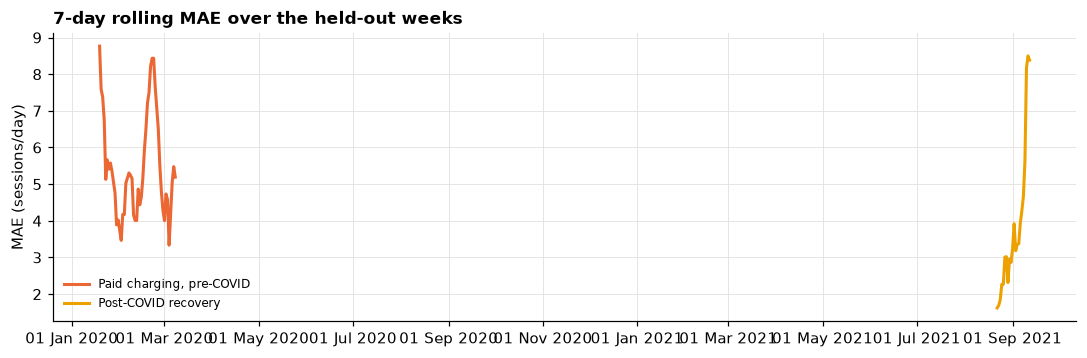

,worst_week_ending,worst_week_MAE,best_week_MAE
regime,,,
paid,2020-01-19,8.77,3.34
recovery,2021-09-11,8.50,1.62


,,MAE,bias,closure_days
regime,origin,,,
paid,2019-12-23,6.45,0.12,9
recovery,2021-07-19,4.23,-3.59,0


In [6]:
worst = holdout.sort_values("abs_error", ascending=False).head(10).copy()
worst["weekday"] = worst["dayofweek"].map(dict(enumerate(DOW)))
def why(r):
    p = []
    if r.campus_closure: p.append(f"campus closure ({r.holiday_name})")
    elif r.holiday_name: p.append(f"holiday, not a closure ({r.holiday_name})")
    if r.dayofweek >= 5: p.append("weekend")
    nb = daily["campus_closure"].reindex(pd.date_range(r.date - pd.Timedelta(days=1), r.date + pd.Timedelta(days=1))).fillna(0)
    if not r.campus_closure and nb.max() == 1: p.append("next to a closure")
    p.append("over-forecast" if r.error > 0 else "under-forecast")
    return "; ".join(p)
worst["explanation"] = worst.apply(why, axis=1)
worst = save_table(worst[["regime", "date", "weekday", "actual", "forecast", "error", "lo80", "hi80", "explanation"]], "07_worst_holdout_days", index=False)
display(worst.round({"actual": 1, "forecast": 1, "error": 1, "lo80": 1, "hi80": 1}))

roll_rows = []
fig, ax = plt.subplots(figsize=(12, 3.4))
for reg in REGS:
    d = holdout[holdout.regime == reg].set_index("date")["abs_error"]
    r7 = d.rolling(7, min_periods=7).mean()
    ax.plot(r7.index, r7.values, color=REG_COLORS[reg], lw=2, label=LABEL[reg])
    roll_rows.append({"regime": reg, "worst_week_ending": r7.idxmax().date(), "worst_week_MAE": r7.max(), "best_week_MAE": r7.min()})
ax.set(title="7-day rolling MAE over the held-out weeks", ylabel="MAE (sessions/day)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y")); ax.legend(fontsize=8)
save_fig(fig, "E05_rolling_mae_holdout")
roll = save_table(pd.DataFrame(roll_rows).set_index("regime"), "08_rolling_mae")

origin_m = sel.groupby(["regime", "origin"]).agg(MAE=("abs_error", "mean"), bias=("error", "mean"), closure_days=("campus_closure", "sum"))
save_table(origin_m.round(3), "09_error_by_origin")
hard_origins = origin_m.groupby(level=0)["MAE"].idxmax()
display(roll.round(2)); display(origin_m.loc[list(hard_origins)].round(2))

### 1.6 Reliability of the forecasting model

Four checks, each with a pass rule fixed before the result is seen:
1. **Skill:** the selected model beats the best baseline by at least 10% MAE in the backtest.
2. **Calibration:** the 80% interval covers 70–90% of backtest days.
3. **Stability:** MAE in week 4 of the horizon is no more than 1.5 × MAE in week 1.
4. **No persistent bias:** |bias| is under 10% of mean demand in the held-out weeks.

In [7]:
rel_rows = []
for reg in REGS:
    s = skill[(skill.regime == reg) & skill.selected].iloc[0]
    cov = bt_m[(bt_m.regime == reg) & (bt_m.model == CHOSEN[reg])]["coverage_80"].iloc[0]
    h = by_h.loc[reg]["MAE"]
    growth = h.iloc[-1] / h.iloc[0]
    bias_share = abs(hold_m.at[reg, "bias"]) / hold_m.at[reg, "mean_actual"]
    checks = {"skill_ok": s.skill_vs_best_baseline >= 0.10, "calibration_ok": 0.70 <= cov <= 0.90,
              "stability_ok": growth <= 1.5, "bias_ok": bias_share < 0.10}
    rel_rows.append({"regime": reg, "model": CHOSEN[reg], "skill_vs_best_baseline": s.skill_vs_best_baseline, "backtest_coverage_80": cov,
                     "MAE_week4_over_week1": growth, "holdout_bias_share": bias_share, **checks, "checks_passed": sum(checks.values())})
reliability = save_table(pd.DataFrame(rel_rows).set_index("regime"), "10_reliability")
def verdict(n): return {4: "reliable", 3: "usable with care"}.get(n, "not reliable on its own")
reliability["verdict"] = reliability["checks_passed"].map(verdict)
display(reliability.style.format({"skill_vs_best_baseline": "{:+.0%}", "backtest_coverage_80": "{:.0%}",
                                  "MAE_week4_over_week1": "{:.2f}", "holdout_bias_share": "{:.1%}"}))

,model,skill_vs_best_baseline,backtest_coverage_80,MAE_week4_over_week1,holdout_bias_share,skill_ok,calibration_ok,stability_ok,bias_ok,checks_passed,verdict
regime,,,,,,,,,,,
paid,SARIMAX + closures,+35%,88%,1.00,13.7%,True,True,True,False,3,usable with care
recovery,SARIMAX + closures + drift,+17%,65%,1.46,5.3%,True,False,True,True,3,usable with care


## 2. Forecast Analysis

The future forecast starts the day after the data end and comes from the recovery-regime model. Historical comparisons use the same regimes as Issue #16. Campus closures are excluded from "typical day" figures.

In [8]:
FC_REG = "recovery" if "recovery" in CHOSEN else REGS[-1]
fc = future.copy()
fc["dayofweek"] = fc.index.dayofweek
fc["is_weekend"] = (fc["dayofweek"] >= 5).astype(int)
obs = daily[daily.observed == 1]
typ = obs[obs.campus_closure == 0]
last8 = typ[typ.index > obs.index.max() - pd.Timedelta(days=56)]
wk = fc.groupby((fc.index - fc.index.min()).days // 7)["forecast_sessions"].sum()
growth_8w = wk.iloc[-1] / wk.iloc[0] - 1
fc_wd, fc_we = fc.loc[(fc.is_weekend == 0) & (fc.campus_closure == 0), "forecast_sessions"], fc.loc[fc.is_weekend == 1, "forecast_sessions"]
summary = pd.Series({
    "forecast_start": fc.index.min().date(), "forecast_end": fc.index.max().date(), "days": len(fc),
    "mean_sessions_per_day": fc.forecast_sessions.mean(), "mean_weekday_sessions": fc_wd.mean(), "mean_weekend_sessions": fc_we.mean(),
    "total_sessions": fc.forecast_sessions.sum(), "mean_kWh_per_day": fc.forecast_kWh.mean(), "total_kWh": fc.forecast_kWh.sum(),
    "first_week_sessions": wk.iloc[0], "last_week_sessions": wk.iloc[-1], "growth_first_to_last_week": growth_8w,
    "last8w_actual_weekday_mean": last8.loc[last8.is_weekend == 0, "session_count"].mean(),
    "last8w_actual_weekend_mean": last8.loc[last8.is_weekend == 1, "session_count"].mean(),
    "closure_days_in_horizon": int(fc.campus_closure.sum())})
save_table(summary.to_frame("value"), "11_future_forecast_summary")
display(summary.to_frame("value"))

,value
forecast_start,2021-09-14
forecast_end,2021-11-08
days,56
mean_sessions_per_day,24.725893
mean_weekday_sessions,28.272
mean_weekend_sessions,15.860625
total_sessions,1384.65
mean_kWh_per_day,299.552321
total_kWh,16774.93
first_week_sessions,169.8


### 2.1 Predicted future demand, peak-demand periods and low-demand periods

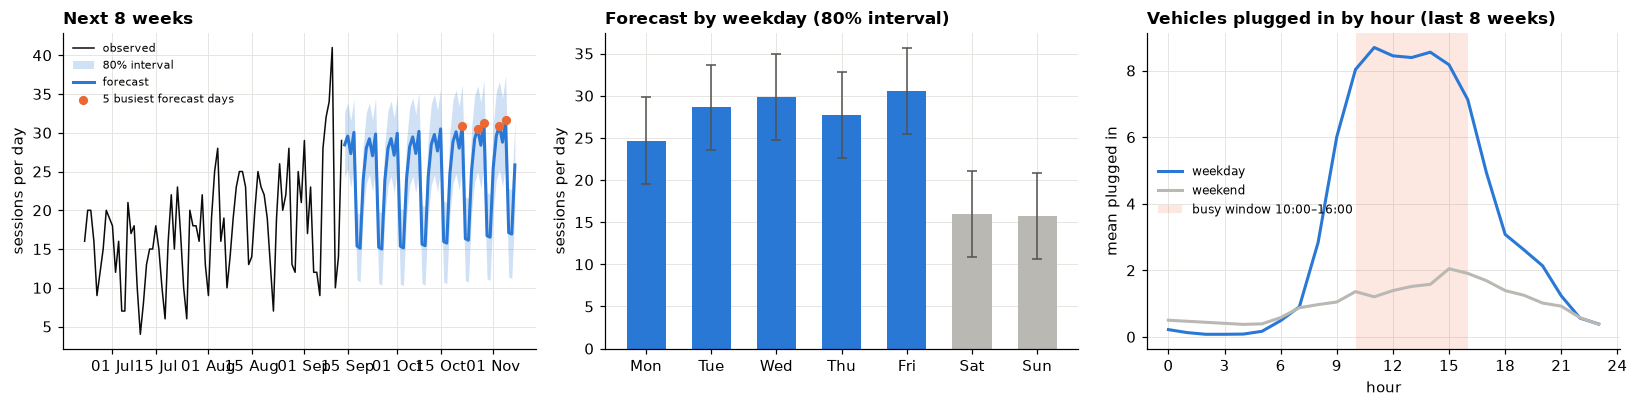

**Busiest forecast days**

,weekday,forecast_sessions,hi80,expected_peak_plugged_in,peak_plugged_in_upper
date,,,,,
2021-11-05,Fri,31.6,37.4,20.8,32.0
2021-10-29,Fri,31.2,36.8,20.5,31.6
2021-11-03,Wed,30.9,36.6,20.3,31.5
2021-10-22,Fri,30.9,36.3,20.2,31.1
2021-10-27,Wed,30.5,36.1,20.0,31.0


**Quietest forecast days**

,weekday,forecast_sessions,lo80,campus_closure
date,,,,
2021-09-26,Sun,15.0,10.3,0
2021-09-19,Sun,15.1,10.7,0
2021-10-03,Sun,15.2,10.3,0
2021-09-25,Sat,15.2,10.6,0
2021-10-02,Sat,15.4,10.5,0


Busy window on weekdays (>= 90% of peak plugged-in): 10:00–16:00; quiet hours (<= 20% of peak): before 08:00 and after 21:00


In [9]:
peak_days = fc.sort_values("forecast_sessions", ascending=False).head(5)
low_days = fc.sort_values("forecast_sessions").head(5)
fc_dow = fc[fc.campus_closure == 0].groupby("dayofweek")[["forecast_sessions", "lo80", "hi80", "expected_peak_plugged_in", "peak_plugged_in_upper"]].mean()
fc_dow.index = [DOW[i] for i in fc_dow.index]
save_table(fc_dow.round(2), "12_forecast_by_weekday")

# Intraday: plugged-in profile of recent typical weekdays/weekends (shape for the forecast period)
h = hourly[hourly.observed == 1].copy()
h = h[h["date"] > obs.index.max() - pd.Timedelta(days=56)]
h["dow"] = h["datetime_local"].dt.dayofweek
h = h[~h["date"].isin(obs.index[obs.campus_closure == 1])]
prof_wd = h[h.dow < 5].groupby("hour")["mean_plugged_in"].mean()
prof_we = h[h.dow >= 5].groupby("hour")["mean_plugged_in"].mean()
arr_wd = h[h.dow < 5].groupby("hour")["arrivals"].mean()
busy = prof_wd[prof_wd >= 0.9 * prof_wd.max()].index
quiet = prof_wd[prof_wd <= 0.2 * prof_wd.max()].index
BUSY_WINDOW = f"{hhmm(busy.min())}–{hhmm(busy.max() + 1)}"
QUIET_HOURS = f"{hhmm(quiet.max() + 1) if (quiet < busy.min()).all() else ''}"
quiet_evening = [x for x in quiet if x > busy.max()]
quiet_morning = [x for x in quiet if x < busy.min()]
QUIET_TXT = (f"before {hhmm(max(quiet_morning) + 1)}" if quiet_morning else "") + \
            (" and " if quiet_morning and quiet_evening else "") + (f"after {hhmm(min(quiet_evening))}" if quiet_evening else "")
intraday = save_table(pd.DataFrame({"weekday_mean_plugged_in": prof_wd, "weekend_mean_plugged_in": prof_we, "weekday_arrivals": arr_wd}).round(3), "13_recent_intraday_profile")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
hist = obs["session_count"].iloc[-84:]
axes[0].plot(hist.index, hist.values, color=INK, lw=1, label="observed")
axes[0].fill_between(fc.index, fc.lo80, fc.hi80, color=SERIES, alpha=0.22, lw=0, label="80% interval")
axes[0].plot(fc.index, fc.forecast_sessions, color=SERIES, lw=2, label="forecast")
axes[0].scatter(peak_days.index, peak_days.forecast_sessions, color=ACCENT, zorder=4, s=25, label="5 busiest forecast days")
axes[0].set(title="Next 8 weeks", ylabel="sessions per day"); axes[0].legend(fontsize=7)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[0].xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6))
axes[1].bar(fc_dow.index, fc_dow.forecast_sessions, color=[SERIES] * 5 + [NEUTRAL] * 2, width=0.6)
axes[1].errorbar(fc_dow.index, fc_dow.forecast_sessions, yerr=[fc_dow.forecast_sessions - fc_dow.lo80, fc_dow.hi80 - fc_dow.forecast_sessions],
                 fmt="none", ecolor=INK2, capsize=3, lw=1)
axes[1].set(title="Forecast by weekday (80% interval)", ylabel="sessions per day")
axes[2].plot(prof_wd.index, prof_wd.values, color=SERIES, lw=2, label="weekday")
axes[2].plot(prof_we.index, prof_we.values, color=NEUTRAL, lw=2, label="weekend")
axes[2].axvspan(busy.min(), busy.max() + 1, color=ACCENT, alpha=0.15, lw=0, label=f"busy window {BUSY_WINDOW}")
axes[2].set(title="Vehicles plugged in by hour (last 8 weeks)", xlabel="hour", ylabel="mean plugged in", xticks=range(0, 25, 3))
axes[2].legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "E06_future_peaks_and_lows")
display(Markdown("**Busiest forecast days**")); display(peak_days[["weekday", "forecast_sessions", "hi80", "expected_peak_plugged_in", "peak_plugged_in_upper"]].round(1))
display(Markdown("**Quietest forecast days**")); display(low_days[["weekday", "forecast_sessions", "lo80", "campus_closure"]].round(1))
print(f"Busy window on weekdays (>= 90% of peak plugged-in): {BUSY_WINDOW}; quiet hours (<= 20% of peak): {QUIET_TXT}")

### 2.2 Forecast versus historical patterns

Three comparisons: the weekly shape (does the forecast keep the weekday/weekend pattern seen in the data?), the level (where the forecast sits relative to recent demand and to the pre-COVID paid-charging level), and the same calendar weeks in earlier years.

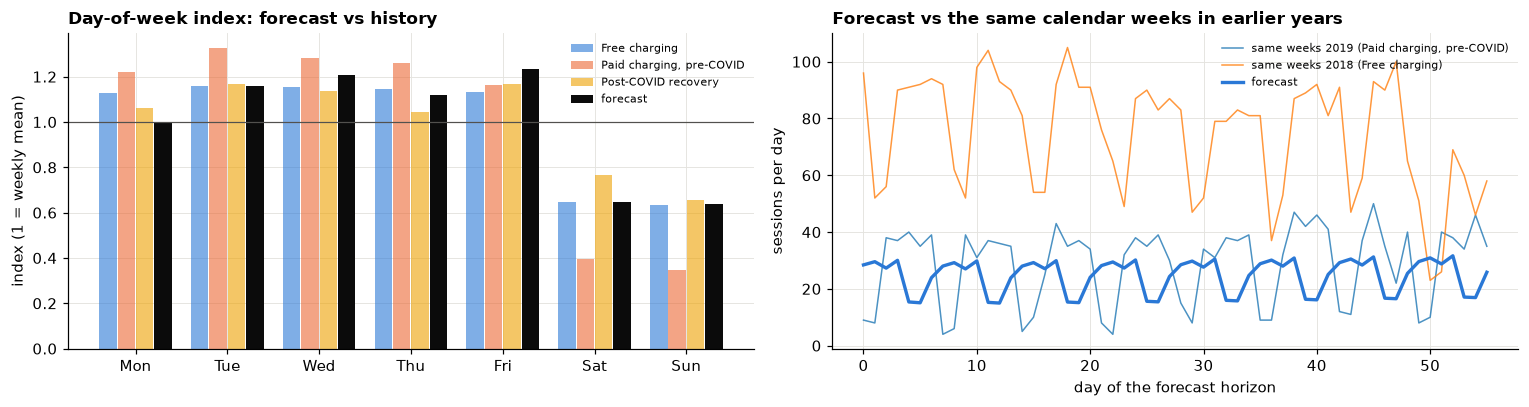

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
free,1.13,1.16,1.16,1.14,1.13,0.65,0.63
paid,1.22,1.33,1.28,1.26,1.16,0.40,0.35
recovery,1.06,1.17,1.14,1.05,1.17,0.76,0.66
forecast,1.00,1.16,1.21,1.12,1.23,0.65,0.64


,sessions per typical weekday
forecast_weekday,28.3
last_8_weeks_weekday,23.0
recovery_regime_weekday,12.7
paid_regime_weekday,39.0
free_regime_weekday,79.8


Forecast weekday level = 73% of the pre-COVID paid-charging level; weekend/weekday ratio 0.56 (history: Free charging 0.56, Paid charging, pre-COVID 0.30, Post-COVID recovery 0.64)


In [10]:
def dow_index(s): return s / s.mean()
hist_dow = typ[typ.regime.isin(["free", "paid", "recovery"])].groupby(["regime", "dayofweek"])["session_count"].mean().unstack()
hist_dow.columns = DOW
cmp_dow = pd.concat([hist_dow.apply(dow_index, axis=1), dow_index(fc_dow["forecast_sessions"]).to_frame("forecast").T])
save_table(cmp_dow.round(3), "14_dow_index_forecast_vs_history")

paid_wd = typ[(typ.regime == "paid") & (typ.is_weekend == 0)]["session_count"].mean()
free_wd = typ[(typ.regime == "free") & (typ.is_weekend == 0)]["session_count"].mean()
rec_wd = typ[(typ.regime == FC_REG) & (typ.is_weekend == 0)]["session_count"].mean()
level = pd.Series({"forecast_weekday": fc_wd.mean(), "last_8_weeks_weekday": summary["last8w_actual_weekday_mean"],
                   f"{FC_REG}_regime_weekday": rec_wd, "paid_regime_weekday": paid_wd, "free_regime_weekday": free_wd})
share_of_paid = fc_wd.mean() / paid_wd
weekend_ratio_fc = fc_we.mean() / fc_wd.mean()
weekend_ratio_hist = {r: typ[(typ.regime == r) & (typ.is_weekend == 1)]["session_count"].mean() /
                         typ[(typ.regime == r) & (typ.is_weekend == 0)]["session_count"].mean() for r in ["free", "paid", FC_REG]}
save_table(level.to_frame("sessions_per_typical_weekday").round(2), "15_level_forecast_vs_history")

same_weeks = {}
for yrs in [1, 2, 3]:
    s0, s1 = fc.index.min() - pd.DateOffset(years=yrs), fc.index.max() - pd.DateOffset(years=yrs)
    w = obs.loc[s0:s1, "session_count"]
    if len(w) >= 0.8 * len(fc):
        same_weeks[f"{s0:%Y} ({LABEL.get(obs.loc[s0:s1, 'regime'].mode().iloc[0], '')})"] = w
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(7); wdt = 0.8 / len(cmp_dow)
for i, (name, row) in enumerate(cmp_dow.iterrows()):
    axes[0].bar(x + (i - (len(cmp_dow) - 1) / 2) * wdt, row.values, width=wdt * 0.95,
                color=REG_COLORS.get(name, INK), alpha=1 if name == "forecast" else 0.6, label=LABEL.get(name, "forecast"))
axes[0].axhline(1, color=INK2, lw=0.8); axes[0].set_xticks(x, DOW)
axes[0].set(title="Day-of-week index: forecast vs history", ylabel="index (1 = weekly mean)"); axes[0].legend(fontsize=7)
for name, w in same_weeks.items():
    axes[1].plot(np.arange(len(w)), w.values, lw=1, alpha=0.8, label=f"same weeks {name}")
axes[1].plot(np.arange(len(fc)), fc.forecast_sessions.values, color=SERIES, lw=2.2, label="forecast")
axes[1].set(title="Forecast vs the same calendar weeks in earlier years", xlabel="day of the forecast horizon", ylabel="sessions per day")
axes[1].legend(fontsize=7)
fig.tight_layout(); save_fig(fig, "E07_forecast_vs_history")
display(cmp_dow.round(2)); display(level.round(1).to_frame("sessions per typical weekday"))
print(f"Forecast weekday level = {share_of_paid:.0%} of the pre-COVID paid-charging level; weekend/weekday ratio {weekend_ratio_fc:.2f} "
      f"(history: " + ", ".join(f"{LABEL[r]} {v:.2f}" for r, v in weekend_ratio_hist.items()) + ")")

### 2.3 Important forecast observations (generated)

In [11]:
max_dev = (cmp_dow.loc["forecast"] - cmp_dow.loc[FC_REG]).abs().max()
obs_lines = [
    f"- Over {summary['forecast_start']:%d %b} – {summary['forecast_end']:%d %b %Y} the model expects **{summary['mean_sessions_per_day']:.1f} sessions/day** "
    f"({summary['mean_weekday_sessions']:.1f} on typical weekdays, {summary['mean_weekend_sessions']:.1f} at weekends), about {summary['mean_kWh_per_day']:.0f} kWh/day.",
    f"- Weekly volume changes by **{summary['growth_first_to_last_week']:+.0%}** from the first to the last forecast week "
    + (("(the drift term continues the recovery trend)." if "drift" in CHOSEN[FC_REG] else "(rising with the recent level).")
       if summary["growth_first_to_last_week"] > 0.02 else "(falling)." if summary["growth_first_to_last_week"] < -0.02 else "(essentially flat)."),
    f"- The forecast weekday level is {fc_wd.mean() / summary['last8w_actual_weekday_mean'] - 1:+.0%} against the last 8 observed weeks and "
    f"**{share_of_paid:.0%} of the pre-COVID paid-charging level** ({paid_wd:.0f} sessions per typical weekday).",
    f"- The weekly shape matches the {LABEL[FC_REG][0].lower() + LABEL[FC_REG][1:]} history (largest day-of-week index difference {max_dev:.2f}); "
    f"weekends carry {weekend_ratio_fc:.0%} of a weekday's demand.",
    f"- Busiest forecast day: **{peak_days.index[0]:%a %d %b}** ({peak_days.forecast_sessions.iloc[0]:.0f} sessions, 80% upper bound {peak_days.hi80.iloc[0]:.0f}); "
    f"highest weekday on average: {fc_dow.forecast_sessions.iloc[:5].idxmax()}. Quietest: {low_days.index[0]:%a %d %b} ({low_days.forecast_sessions.iloc[0]:.0f}).",
    ("- No campus closure falls in the horizon." if summary["closure_days_in_horizon"] == 0 else
     f"- {summary['closure_days_in_horizon']} campus-closure day(s) fall in the horizon and are forecast low."),
    f"- Within the day, vehicles plugged in stay near their maximum during **{BUSY_WINDOW}** on weekdays; demand is low {QUIET_TXT}.",
]
OBS_TEXT = "\n".join(obs_lines)
display(Markdown(OBS_TEXT))

- Over 14 Sep – 08 Nov 2021 the model expects **24.7 sessions/day** (28.3 on typical weekdays, 15.9 at weekends), about 300 kWh/day.
- Weekly volume changes by **+7%** from the first to the last forecast week (the drift term continues the recovery trend).
- The forecast weekday level is +23% against the last 8 observed weeks and **73% of the pre-COVID paid-charging level** (39 sessions per typical weekday).
- The weekly shape matches the post-COVID recovery history (largest day-of-week index difference 0.12); weekends carry 56% of a weekday's demand.
- Busiest forecast day: **Fri 05 Nov** (32 sessions, 80% upper bound 37); highest weekday on average: Fri. Quietest: Sun 26 Sep (15).
- No campus closure falls in the horizon.
- Within the day, vehicles plugged in stay near their maximum during **10:00–16:00** on weekdays; demand is low before 08:00 and after 21:00.

## 3. Business Interpretation

### 3.1 Inputs for capacity and charger-allocation decisions

Capacity is set by the most vehicles plugged in at the same time, not by sessions per day. The Issue #16 forecast converts sessions into expected peak plugged-in vehicles and an upper planning bound. Two adjustments are made here from the evaluation:
- **Planning buffer:** the 90th percentile of under-forecasting in the backtest (how many sessions above the forecast to plan for on 9 days in 10).
- **Charger usage:** how evenly the chargers were used over the last 8 weeks (from `acn_clean_sessions.csv`), and how long vehicles stayed plugged in after charging finished.

In [12]:
sess = pd.read_csv(ROOT / "acn_clean_sessions.csv", usecols=["stationID", "date", "connected_h", "charging_h", "hour"], parse_dates=["date"])
last_day = obs.index.max()
recent = sess[sess["date"] > last_day - pd.Timedelta(days=56)]
paid_s = sess[sess["date"].between(regimes.at["paid", "start"], regimes.at["paid", "end"])]
st_installed = sess["stationID"].nunique()
st_recent = recent["stationID"].nunique()
st_paid = paid_s["stationID"].nunique()
per_st = recent.groupby("stationID").size().sort_values(ascending=False)
top_n = max(1, int(round(0.2 * st_recent)))
top_share = per_st.iloc[:top_n].sum() / per_st.sum()
idle_share = 1 - recent["charging_h"].clip(lower=0).sum() / recent["connected_h"].sum()
mean_stay = recent["connected_h"].mean()

under = (-sel[sel.regime == FC_REG]["error"])          # actual - forecast; positive = demand above forecast
buf90, buf80 = np.quantile(under, 0.9), np.quantile(under, 0.8)
# peak plugged-in ~ b0 + b1 * sessions (Issue #16 relation, recovered from its forecast table)
b1, b0 = np.polyfit(fc["forecast_sessions"], fc["expected_peak_plugged_in"], 1)
fc["planned_sessions_p90"] = fc["forecast_sessions"] + buf90
fc["planned_peak_p90"] = np.clip(b0 + b1 * fc["planned_sessions_p90"], 0, None)
need_wd = int(np.ceil(fc.loc[(fc.is_weekend == 0) & (fc.campus_closure == 0), "planned_peak_p90"].max()))
need_we = int(np.ceil(fc.loc[fc.is_weekend == 1, "planned_peak_p90"].max()))
need_upper = int(np.ceil(fc["peak_plugged_in_upper"].max()))
paid_peak_p95 = obs[(obs.regime == "paid") & (obs.is_weekend == 0) & (obs.campus_closure == 0)]["peak_occupancy"].quantile(0.95)
alloc = pd.Series({"stations_installed": st_installed, "stations_used_last_8_weeks": st_recent, "stations_used_paid_regime": st_paid,
                   "sessions_per_used_station_per_day": len(recent) / st_recent / 56,
                   f"share_of_sessions_on_top_{top_n}_stations": top_share, "mean_connection_h": mean_stay,
                   "share_of_plugged_in_time_not_charging": idle_share,
                   "planning_buffer_sessions_p80": buf80, "planning_buffer_sessions_p90": buf90,
                   "chargers_needed_weekday_p90": need_wd, "chargers_needed_weekend_p90": need_we,
                   "chargers_needed_upper_bound_i16": need_upper, "chargers_needed_at_paid_level_p95": paid_peak_p95})
save_table(alloc.to_frame("value"), "16_capacity_and_allocation")
fc.round(2).to_csv(TAB / "17_future_forecast_with_buffer.csv")
display(alloc.to_frame("value").round(2))

,value
stations_installed,55.00
stations_used_last_8_weeks,36.00
stations_used_paid_regime,54.00
sessions_per_used_station_per_day,0.54
share_of_sessions_on_top_7_stations,0.63
mean_connection_h,3.37
share_of_plugged_in_time_not_charging,0.61
planning_buffer_sessions_p80,5.12
planning_buffer_sessions_p90,6.48
chargers_needed_weekday_p90,26.00


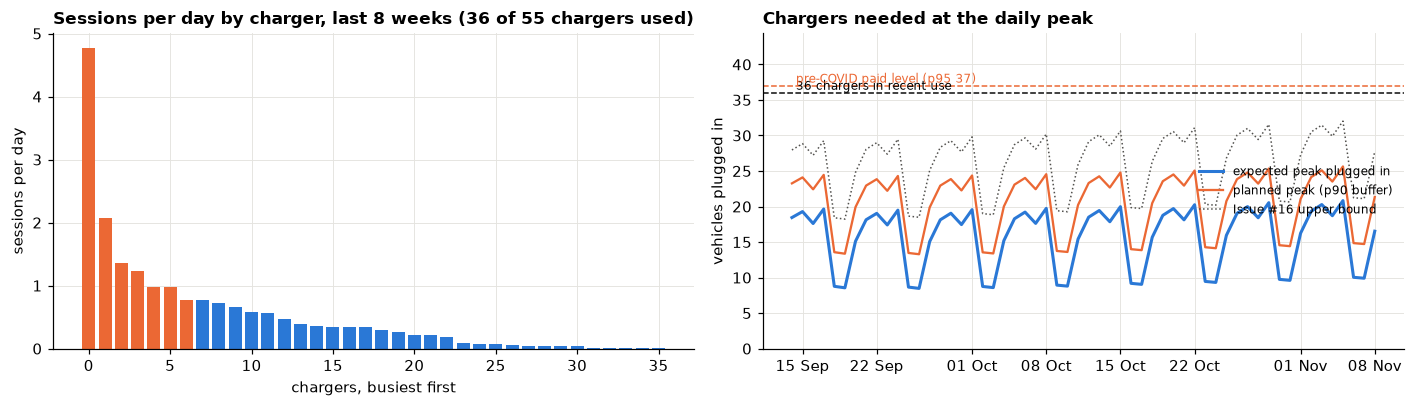

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(len(per_st)), per_st.values / 56, color=[ACCENT if i < top_n else SERIES for i in range(len(per_st))], width=0.8)
axes[0].set(title=f"Sessions per day by charger, last 8 weeks ({st_recent} of {st_installed} chargers used)",
            xlabel="chargers, busiest first", ylabel="sessions per day")
d = fc.index
axes[1].plot(d, fc["expected_peak_plugged_in"], color=SERIES, lw=2, label="expected peak plugged in")
axes[1].plot(d, fc["planned_peak_p90"], color=ACCENT, lw=1.5, label="planned peak (p90 buffer)")
axes[1].plot(d, fc["peak_plugged_in_upper"], color=INK2, lw=1, ls=":", label="Issue #16 upper bound")
axes[1].axhline(st_recent, color=INK, ls="--", lw=1); axes[1].text(d[0], st_recent, f" {st_recent} chargers in recent use", va="bottom", fontsize=8)
axes[1].axhline(paid_peak_p95, color=REG_COLORS["paid"], ls="--", lw=1)
axes[1].text(d[0], paid_peak_p95, f" pre-COVID paid level (p95 {paid_peak_p95:.0f})", va="bottom", fontsize=8, color=REG_COLORS["paid"])
axes[1].set(title="Chargers needed at the daily peak", ylabel="vehicles plugged in", ylim=(0, max(st_recent, paid_peak_p95) * 1.2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[1].legend(fontsize=8, loc="center right")
fig.tight_layout(); save_fig(fig, "E08_capacity_and_allocation")

### 3.2 Findings for integration into the project (generated)

In [14]:
R = reliability
def reg_line(reg):
    m = hold_m.loc[reg]
    return (f"- **{LABEL[reg]}** ({CHOSEN[reg]}): held-out MAE {m.MAE:.1f} sessions/day, WAPE {m.WAPE:.0%}, bias {m.bias:+.1f}; "
            f"80% interval covered {m.coverage_80:.0%} of days (95%: {m.coverage_95:.0%}). Backtest skill vs best baseline "
            f"{R.at[reg, 'skill_vs_best_baseline']:+.0%}; error in week 4 of the horizon is {R.at[reg, 'MAE_week4_over_week1']:.1f}× week 1. "
            f"Verdict: **{R.at[reg, 'verdict']}** ({R.at[reg, 'checks_passed']}/4 checks).")
fail_txt = []
for reg in REGS:
    if not R.at[reg, "calibration_ok"]:
        c = R.at[reg, "backtest_coverage_80"]
        fail_txt.append(f"{LABEL[reg]}: the 80% interval covered {c:.0%} of backtest days, so it is " + ("too narrow" if c < 0.7 else "too wide") + ".")
    if not R.at[reg, "bias_ok"]:
        fail_txt.append(f"{LABEL[reg]}: held-out bias is {R.at[reg, 'holdout_bias_share']:.0%} of mean demand.")
    if not R.at[reg, "skill_ok"]:
        fail_txt.append(f"{LABEL[reg]}: the model beats the best baseline by only {R.at[reg, 'skill_vs_best_baseline']:.0%}.")
    if not R.at[reg, "stability_ok"]:
        fail_txt.append(f"{LABEL[reg]}: error grows {R.at[reg, 'MAE_week4_over_week1']:.1f}× over the 4-week horizon.")
cl_reg = [r for r in REGS if (r, 1) in by_cl.index]
cl_txt = "; ".join(f"{LABEL[r]} MAE {by_cl.loc[(r, 1), 'MAE']:.1f} on closure days vs {by_cl.loc[(r, 0), 'MAE']:.1f} on other days" for r in cl_reg)
worst_txt = "; ".join(f"{r.date:%a %d %b %Y} ({r.explanation}, error {r.error:+.0f})" for r in worst.head(3).itertuples())
dow_worst = {r: DOW[int(by_dow.loc[r]["rel_MAE"].idxmax())] for r in REGS}
cap_ratio = need_wd / st_recent
cap_txt = (f"With a 90%-of-days buffer the busiest weekday needs about **{need_wd} chargers** at the peak, {cap_ratio:.0%} of the {st_recent} "
           f"in recent use; weekends need about {need_we}. " +
           ("No new chargers are needed for the forecast period." if cap_ratio < 0.8 else
            "This is close to the chargers in use: bring idle chargers back into service before the busiest days." if cap_ratio <= 1 else
            f"This exceeds the chargers in recent use; re-activate idle chargers (there are {st_installed} installed)."))
paid_txt = (f"If demand returns to the pre-COVID paid level, busy weekdays need about {paid_peak_p95:.0f} chargers at the peak (95th percentile), "
            + (f"more than the {st_recent} in recent use but within the {st_installed} installed." if paid_peak_p95 > st_recent else
               f"which the {st_recent} chargers in recent use can serve."))
lab = lambda r: LABEL[r][0].lower() + LABEL[r][1:]
pat = []
for r in REGS:
    a = err_pattern.at[r, "error_autocorr_lag1"]
    pat.append(f"{LABEL[r]}: lag-1 autocorrelation of held-out errors {a:.2f} → " +
               ("misses come in runs, a sign of level shifts the model adapts to slowly." if a > 0.3 else
                "errors are close to random from day to day, so no pattern is left for the model to use."))
pattern_txt = " ".join(pat)
idle_txt = (f"Peak occupancy ({BUSY_WINDOW} on weekdays) is driven mostly by parked cars, not by power demand, so idle fees or move-your-car reminders during that window free chargers more cheaply than new hardware."
            if idle_share > 0.5 else f"Most plugged-in time is spent charging, so peak occupancy ({BUSY_WINDOW} on weekdays) reflects real energy demand; spreading arrivals (e.g. off-peak pricing) is the main lever.")
text = f"""# Issue #17: Forecast evaluation and business findings (generated)

## Forecast evaluation
{chr(10).join(reg_line(r) for r in REGS)}
- **Where the errors are.** {cl_txt}. Largest held-out misses: {worst_txt}. Relative error is highest on {', '.join(f"{d} ({lab(r)})" for r, d in dow_worst.items())}.
- **Error pattern.** {pattern_txt}
{chr(10).join('- ' + t for t in fail_txt) if fail_txt else '- All reliability checks pass in both regimes.'}

## Forecast analysis
{OBS_TEXT}

## Business interpretation
1. **Capacity planning.** {cap_txt} {paid_txt} Plan with the forecast plus {buf90:.0f} sessions/day (the 90th percentile of past under-forecasts), not with the point forecast.
2. **Peak-period management.** Vehicles stay plugged in {mean_stay:.1f} h on average and **{idle_share:.0%} of plugged-in time is spent not charging**. {idle_txt}
3. **Charger allocation.** {st_recent} of {st_installed} chargers were used in the last 8 weeks and the busiest {top_n} carry {top_share:.0%} of sessions. Keep about {need_wd} chargers available on weekdays and {need_we} at weekends; rotate sessions away from the busiest chargers to spread wear; schedule maintenance at weekends, on closure days and in the quiet hours ({QUIET_TXT}).
4. **Use of the forecast.** Use it for the next 1–4 weeks, refit it weekly as new data arrive, and treat it as {R.at[FC_REG, 'verdict']} for the current regime. Any change in pricing or access starts a new regime: switch to the 8-week weekday mean until the model has been refitted on a few weeks of new data.

## Limitations and uncertainty
- The backtest tested horizons up to 4 weeks (error in week 4 = {R.at[FC_REG, 'MAE_week4_over_week1']:.1f}× week 1); weeks 5–8 of the future forecast go beyond what was tested and are indicative only.
- Held-out periods are short ({', '.join(f"{int(hold_m.at[r, 'days'])} days {lab(r)}" for r in REGS)}); the backtest gives the more reliable averages.
- Peak plugged-in vehicles are derived from forecast sessions through a fitted relation, not forecast directly; charger counts inherit that uncertainty.
- One site and one charging network; a closure list derived from this site's data. Results do not transfer to other workplaces without re-fitting.
- Issue #15 covers the next-day ML model; the two forecasts are complementary (day-ahead vs weeks-ahead) and use different test periods, so their errors are not directly comparable.
"""
(ROOT / "forecast_findings_i17.md").write_text(text, encoding="utf-8")
holdout.round({c: 3 for c in ["actual", "forecast", "lo80", "hi80", "lo95", "hi95", "error", "abs_error"]}).to_csv(ROOT / "forecast_evaluation_i17.csv", index=False)
pd.concat([hold_m.assign(source="holdout"), bt_m[bt_m.model.isin(CHOSEN.values())].set_index("regime").assign(source="backtest")]
          ).round(4).to_csv(ROOT / "forecast_metrics_i17.csv")
display(Markdown(text))

# Issue #17: Forecast evaluation and business findings (generated)

## Forecast evaluation
- **Paid charging, pre-COVID** (SARIMAX + closures): held-out MAE 5.7 sessions/day, WAPE 19%, bias -4.0; 80% interval covered 86% of days (95%: 96%). Backtest skill vs best baseline +35%; error in week 4 of the horizon is 1.0× week 1. Verdict: **usable with care** (3/4 checks).
- **Post-COVID recovery** (SARIMAX + closures + drift): held-out MAE 3.9 sessions/day, WAPE 19%, bias -1.1; 80% interval covered 61% of days (95%: 79%). Backtest skill vs best baseline +17%; error in week 4 of the horizon is 1.5× week 1. Verdict: **usable with care** (3/4 checks).
- **Where the errors are.** Paid charging, pre-COVID MAE 4.0 on closure days vs 4.5 on other days; Post-COVID recovery MAE 5.3 on closure days vs 3.1 on other days. Largest held-out misses: Fri 10 Sep 2021 (under-forecast, error -20); Thu 16 Jan 2020 (under-forecast, error -19); Mon 13 Jan 2020 (under-forecast, error -14). Relative error is highest on Sat (paid charging, pre-COVID), Sun (post-COVID recovery).
- **Error pattern.** Paid charging, pre-COVID: lag-1 autocorrelation of held-out errors 0.34 → misses come in runs, a sign of level shifts the model adapts to slowly. Post-COVID recovery: lag-1 autocorrelation of held-out errors 0.16 → errors are close to random from day to day, so no pattern is left for the model to use.
- Paid charging, pre-COVID: held-out bias is 14% of mean demand.
- Post-COVID recovery: the 80% interval covered 65% of backtest days, so it is too narrow.

## Forecast analysis
- Over 14 Sep – 08 Nov 2021 the model expects **24.7 sessions/day** (28.3 on typical weekdays, 15.9 at weekends), about 300 kWh/day.
- Weekly volume changes by **+7%** from the first to the last forecast week (the drift term continues the recovery trend).
- The forecast weekday level is +23% against the last 8 observed weeks and **73% of the pre-COVID paid-charging level** (39 sessions per typical weekday).
- The weekly shape matches the post-COVID recovery history (largest day-of-week index difference 0.12); weekends carry 56% of a weekday's demand.
- Busiest forecast day: **Fri 05 Nov** (32 sessions, 80% upper bound 37); highest weekday on average: Fri. Quietest: Sun 26 Sep (15).
- No campus closure falls in the horizon.
- Within the day, vehicles plugged in stay near their maximum during **10:00–16:00** on weekdays; demand is low before 08:00 and after 21:00.

## Business interpretation
1. **Capacity planning.** With a 90%-of-days buffer the busiest weekday needs about **26 chargers** at the peak, 72% of the 36 in recent use; weekends need about 15. No new chargers are needed for the forecast period. If demand returns to the pre-COVID paid level, busy weekdays need about 37 chargers at the peak (95th percentile), more than the 36 in recent use but within the 55 installed. Plan with the forecast plus 6 sessions/day (the 90th percentile of past under-forecasts), not with the point forecast.
2. **Peak-period management.** Vehicles stay plugged in 3.4 h on average and **61% of plugged-in time is spent not charging**. Peak occupancy (10:00–16:00 on weekdays) is driven mostly by parked cars, not by power demand, so idle fees or move-your-car reminders during that window free chargers more cheaply than new hardware.
3. **Charger allocation.** 36 of 55 chargers were used in the last 8 weeks and the busiest 7 carry 63% of sessions. Keep about 26 chargers available on weekdays and 15 at weekends; rotate sessions away from the busiest chargers to spread wear; schedule maintenance at weekends, on closure days and in the quiet hours (before 08:00 and after 21:00).
4. **Use of the forecast.** Use it for the next 1–4 weeks, refit it weekly as new data arrive, and treat it as usable with care for the current regime. Any change in pricing or access starts a new regime: switch to the 8-week weekday mean until the model has been refitted on a few weeks of new data.

## Limitations and uncertainty
- The backtest tested horizons up to 4 weeks (error in week 4 = 1.5× week 1); weeks 5–8 of the future forecast go beyond what was tested and are indicative only.
- Held-out periods are short (56 days paid charging, pre-COVID, 28 days post-COVID recovery); the backtest gives the more reliable averages.
- Peak plugged-in vehicles are derived from forecast sessions through a fitted relation, not forecast directly; charger counts inherit that uncertainty.
- One site and one charging network; a closure list derived from this site's data. Results do not transfer to other workplaces without re-fitting.
- Issue #15 covers the next-day ML model; the two forecasts are complementary (day-ahead vs weeks-ahead) and use different test periods, so their errors are not directly comparable.


## Issue #17 checklist → where it is done

| Task | Section |
|---|---|
| Select appropriate forecasting evaluation metrics | 1.1 |
| Calculate the selected evaluation metrics | 1.1, 1.2 |
| Compare actual demand with forecast demand | 1.3 (`E02`, `E03`) |
| Analyze forecasting errors | 1.4 (`E04`) |
| Identify periods with higher forecasting error | 1.5 (`E05`, worst days, hardest origins) |
| Assess the reliability of the forecasting model | 1.6 |
| Analyze predicted future charging demand | 2, 2.1 |
| Identify forecasted peak-demand periods | 2.1 (`E06`) |
| Identify periods of relatively low demand | 2.1 |
| Compare forecast patterns with historical patterns | 2.2 (`E07`) |
| Document important forecast observations | 2.3 |
| Explain how the forecasts can support capacity planning | 3.1, 3.2 (`E08`) |
| Identify implications for peak-period management | 3.2 |
| Identify potential charger-allocation implications | 3.1, 3.2 |
| Document limitations and uncertainty in the forecasts | 3.2 |
| Prepare final time-series findings for integration | `forecast_findings_i17.md` |

**Deliverables:** this notebook, `forecast_evaluation_i17.csv`, `forecast_metrics_i17.csv`, `eval_ts_figures/` (E01–E08), `eval_ts_tables/`, `forecast_findings_i17.md`.